**import libraries**

In [146]:
# importing all necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from google.colab import files
import requests
import zipfile
import io
import os
from datetime import datetime

#to keep the same everytime the code is run
np.random.seed(42)

# print versions for debugging
print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version: {np.__version__}")

OpenCV version: 4.11.0
NumPy version: 2.0.2


**Step 1: Data Loading**

Successfully downloaded training_data.npz
Successfully downloaded test_data.npz

Data loading successful!
Training images shape: (2811, 256, 256, 3)
Training points shape: (2811, 5, 2)
Test images shape: (554, 256, 256, 3)


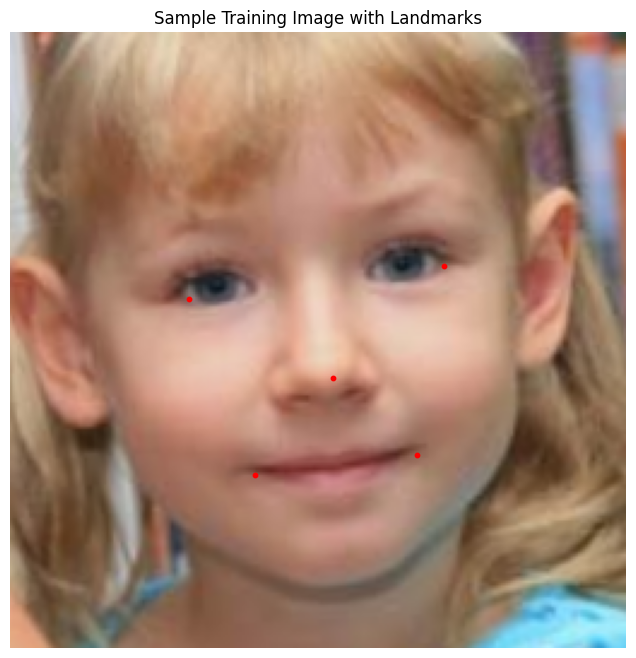

In [147]:
def download_data(url, filename):
    """Robust data downloader with error handling"""
    try:
        print(f"Downloading {filename}...")
        response = requests.get(url, stream=True)
        response.raise_for_status()  # stop if the URL doesnt work

        # save the file in chunks
        with open(filename, 'wb') as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
        print(f"Successfully downloaded {filename}")
        return True
    except Exception as e:
        print(f"Error downloading {filename}: {str(e)}")
        return False

# ddownload datasets
train_url = "https://sussex.box.com/shared/static/wrlmcs47dstkmfz2eckgg5d2l0liusr5"
test_url = "https://sussex.box.com/shared/static/8n5ofhb9so0ia85g4bbcmnt3h6z53m9a"

# if both download correctly then loading them
if download_data(train_url, 'training_data.npz') and download_data(test_url, 'test_data.npz'):
    try:
        train_data = np.load('training_data.npz')
        test_data = np.load('test_data.npz')

        train_images = train_data['images']
        train_points = train_data['points']
        test_images = test_data['images']

        print("\nData loading successful!")
        print(f"Training images shape: {train_images.shape}")
        print(f"Training points shape: {train_points.shape}")
        print(f"Test images shape: {test_images.shape}")

        # show a sample training image with landmarks
        plt.figure(figsize=(8, 8))
        plt.imshow(train_images[0], cmap='gray')
        plt.scatter(train_points[0][:, 0], train_points[0][:, 1], c='r', s=10)
        plt.title("Sample Training Image with Landmarks")
        plt.axis('off')
        plt.show()

    except Exception as e:
        print(f"Error loading data: {str(e)}")
else:
    print("Failed to download data. Using fallback method...")

**Step 2: Enhanced Preprocessing Pipeline**


Starting preprocessing...


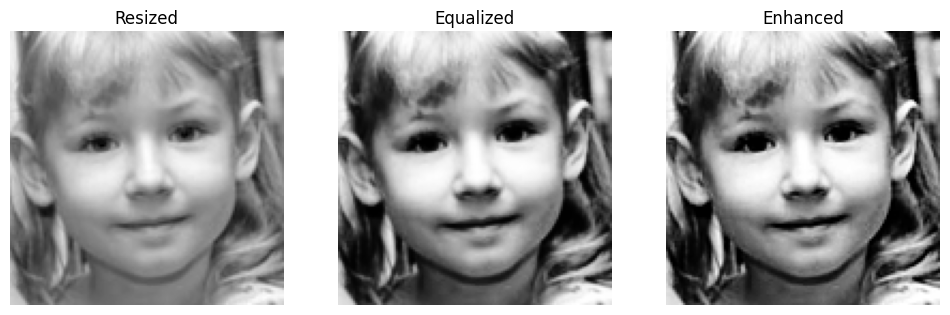

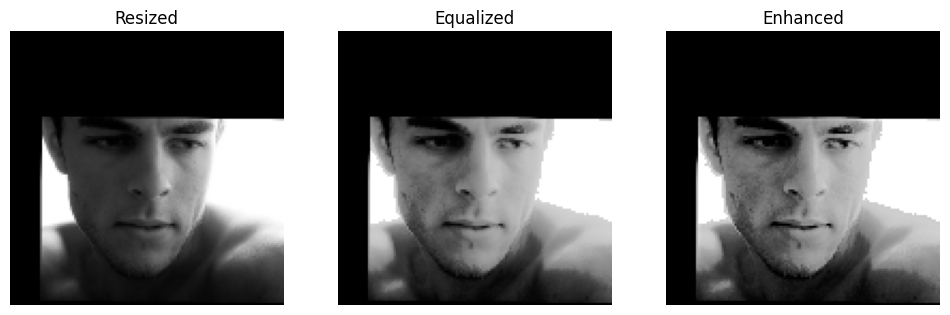

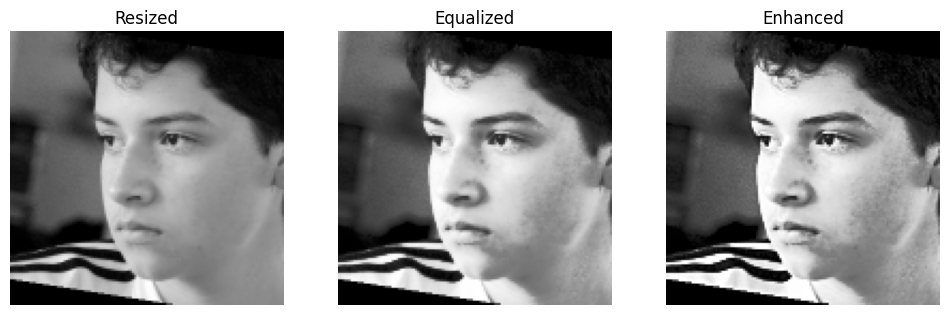


Preprocessing completed with:
Target size: (128, 128)
Scaling factors - X: 0.50, Y: 0.50

Preprocessing completed with:
Target size: (128, 128)
Scaling factors - X: 0.50, Y: 0.50

Sample scaled points:
Original first point: [ 73.82410476 110.4907489 ]
Scaled first point: [36.91205238 55.24537445]


In [148]:
def preprocess_images(images, target_size=(128, 128), visualize=False):
    """
    Enhanced preprocessing with:
    - Resizing
    - Grayscale conversion
    - Histogram equalization
    - Edge enhancement
    - Normalization
    """
    processed_images = []
    original_size = images.shape[1:3]

    for i, img in enumerate(images):
        try:
            # convert to grayscale if needed
            if len(img.shape) == 3 and img.shape[2] == 3:
                gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
            else:
                gray = img

            # resize to the target size
            resized = cv2.resize(gray, target_size, interpolation=cv2.INTER_AREA)

            # histogram equalization to fix lighting and contrast
            equalized = cv2.equalizeHist(resized)

            # sharpening image using unsharp masking
            blurred = cv2.GaussianBlur(equalized, (5, 5), 0)
            enhanced = cv2.addWeighted(equalized, 1.5, blurred, -0.5, 0)

            # normalize
            normalized = enhanced.astype(np.float32) / 255.0
            processed_images.append(normalized)

            # show the first 3 images step-by-step
            if visualize and i < 3:
                plt.figure(figsize=(12, 4))
                plt.subplot(1, 3, 1)
                plt.imshow(resized, cmap='gray')
                plt.title("Resized")
                plt.axis('off')

                plt.subplot(1, 3, 2)
                plt.imshow(equalized, cmap='gray')
                plt.title("Equalized")
                plt.axis('off')

                plt.subplot(1, 3, 3)
                plt.imshow(enhanced, cmap='gray')
                plt.title("Enhanced")
                plt.axis('off')
                plt.show()

        except Exception as e:
            print(f"Error processing image {i}: {str(e)}")
            processed_images.append(np.zeros(target_size, dtype=np.float32))

    # calculate how much we scaled the original images
    scale_x = target_size[0] / original_size[1]
    scale_y = target_size[1] / original_size[0]

    print("\nPreprocessing completed with:")
    print(f"Target size: {target_size}")
    print(f"Scaling factors - X: {scale_x:.2f}, Y: {scale_y:.2f}")

    return np.array(processed_images), (scale_x, scale_y)

# run preprocessing and show some processed images
print("\nStarting preprocessing...")
train_images_processed, scale_factors = preprocess_images(train_images, visualize=True)
test_images_processed, _ = preprocess_images(test_images)

# scale points accordingly
train_points_scaled = train_points.copy()
train_points_scaled[:, :, 0] *= scale_factors[0]
train_points_scaled[:, :, 1] *= scale_factors[1]

print("\nSample scaled points:")
print(f"Original first point: {train_points[0,0]}")
print(f"Scaled first point: {train_points_scaled[0,0]}")

**Step 3: Feature Extraction with Visualization**


Extracting SIFT features with 12x12 grid...


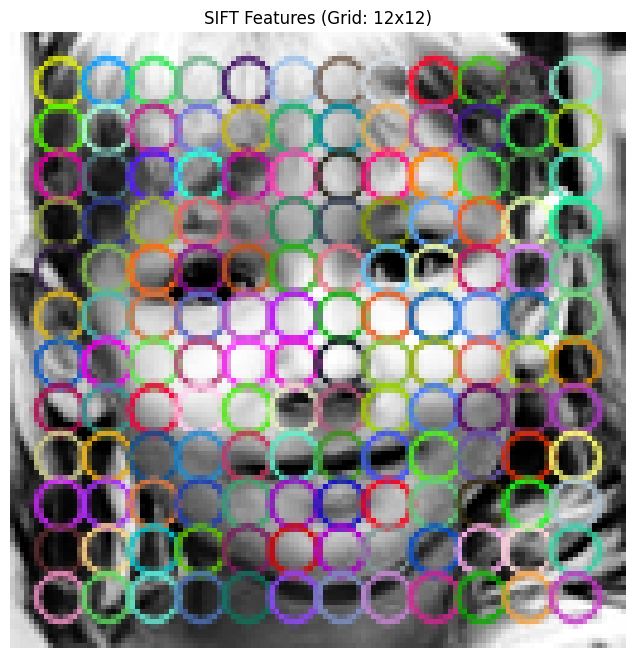


Feature vector shape for one image: (18432,)
Descriptor sample (first 10 values): [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]

Final feature matrix shape: (2811, 18432)


In [149]:
def extract_sift_features(images, grid_size=12, visualize=False):
    """Enhanced SIFT feature extraction with error handling"""
    sift = cv2.SIFT_create()
    features = []

    feature_length = grid_size * grid_size * 128

    # make evenly spaced grid points across the image
    h, w = images[0].shape
    x_coords = np.linspace(10, w-11, grid_size, dtype=np.float32)
    y_coords = np.linspace(10, h-11, grid_size, dtype=np.float32)

    for i, img in enumerate(images):
        try:
            img_uint8 = (img * 255).astype(np.uint8)
            keypoints = [cv2.KeyPoint(x, y, 10) for y in y_coords for x in x_coords]

            # compute descriptors
            _, descriptors = sift.compute(img_uint8, keypoints)

            # if nothing is returned then fill with zeros
            if descriptors is None:
                descriptors = np.zeros((len(keypoints), 128))

            features.append(descriptors.flatten())

            # if visualize is true show the SIFT keypoints for the first image
            if visualize and i == 0:
                img_kp = cv2.drawKeypoints(
                    img_uint8, keypoints, None,
                    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
                )
                plt.figure(figsize=(8, 8))
                plt.imshow(img_kp, cmap='gray')
                plt.title(f"SIFT Features (Grid: {grid_size}x{grid_size})")
                plt.axis('off')
                plt.show()

                print(f"\nFeature vector shape for one image: {features[0].shape}")
                print(f"Descriptor sample (first 10 values): {features[0][:10]}")

        except Exception as e:
            print(f"Error extracting features from image {i}: {str(e)}")
            features.append(np.zeros((grid_size*grid_size*128,), dtype=np.float32))

    return np.array(features)

print("\nExtracting SIFT features with 12x12 grid...")
train_features = extract_sift_features(train_images_processed, grid_size=12, visualize=True)
test_features = extract_sift_features(test_images_processed, grid_size=12)

print(f"\nFinal feature matrix shape: {train_features.shape}")

**Step 4: Model Training
I used ridge regression**


Splitting data into training and validation sets...

Data shapes:
- X_train: (2248, 18432), y_train: (2248, 10)
- X_val: (563, 18432), y_val: (563, 10)

Training model with alpha=0.5...


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_ridge.py:254: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(


Model training completed!

Validation Results:
- MSE: 7.1941
- Mean landmark error: 3.13 pixels
- Robustness (% points <5px error): 84.0%


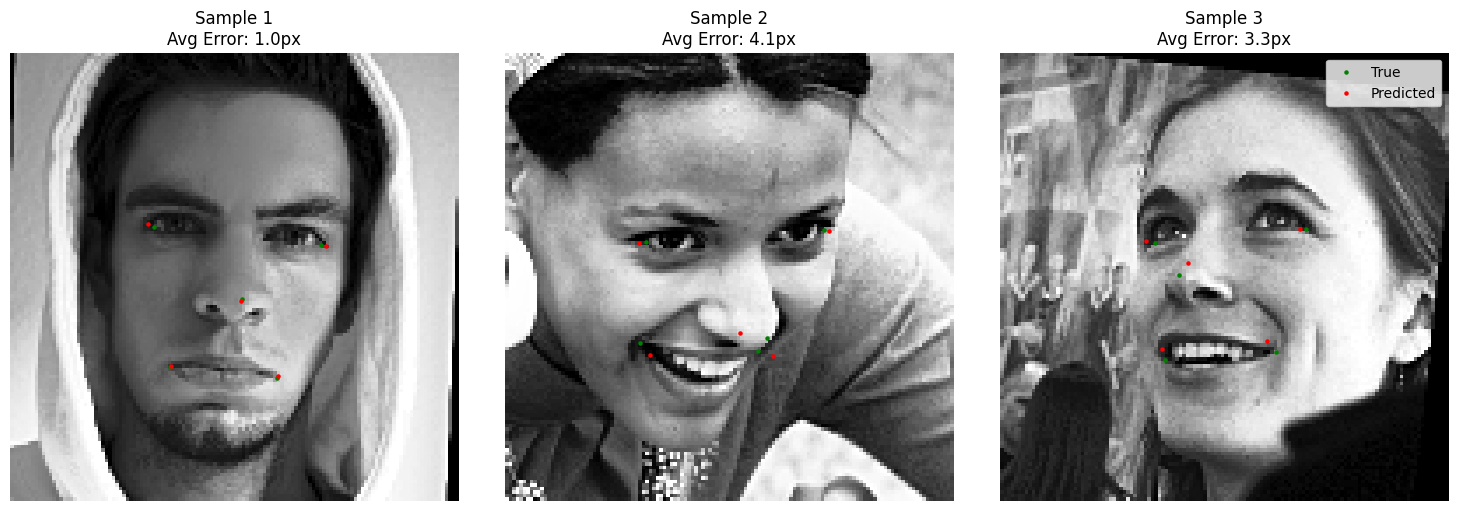


Model coefficients analysis:
- Number of features: 18432
- Coefficient magnitudes:
  Mean: 0.0008
  Max: 0.0112
  Min: 0.0000


In [150]:

# calculating the error for each landmark point using Euclidean distance
def calculate_point_errors(true_points, pred_points):
    """Calculate Euclidean distance errors for each landmark point"""
    return np.sqrt(np.sum((true_points - pred_points)**2, axis=1))

# training Ridge Regression model
def train_model(X_train, y_train, alpha=1.0):
    """Train ridge regression model for landmark prediction"""
    print(f"\nTraining model with alpha={alpha}...")
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    print("Model training completed!")
    return model

# checking how good the model is
def evaluate_model(model, X_val, y_val, original_shape):
    """Comprehensive model evaluation with metrics"""

    # make predictions
    predictions = model.predict(X_val)
    predictions = predictions.reshape(-1, *original_shape)
    y_val_reshaped = y_val.reshape(-1, *original_shape)

    # calculating MSE
    mse = mean_squared_error(y_val_reshaped.reshape(-1), predictions.reshape(-1))

    # getting error per landmark for each sample
    errors = np.sqrt(np.sum((y_val_reshaped - predictions)**2, axis=2))
    mean_error = np.mean(errors)
    robustness = np.mean(errors < 5) * 100  # % points with error < 5px

    print("\nValidation Results:")
    print(f"- MSE: {mse:.4f}")
    print(f"- Mean landmark error: {mean_error:.2f} pixels")
    print(f"- Robustness (% points <5px error): {robustness:.1f}%")

    return mse, predictions, errors

# =====================================
# DATA SPLITTING AND MODEL TRAINING

# first properly split the indices
print("\nSplitting data into training and validation sets...")
train_indices, val_indices = train_test_split(
    range(len(train_images_processed)),
    test_size=0.2,
    random_state=42
)

# creating actual data splits using the indices
X_train = train_features[train_indices]
X_val = train_features[val_indices]
y_train = train_points_scaled.reshape(len(train_points_scaled), -1)[train_indices]
y_val = train_points_scaled.reshape(len(train_points_scaled), -1)[val_indices]

#check the shapes to be make sure everything matches
print(f"\nData shapes:")
print(f"- X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"- X_val: {X_val.shape}, y_val: {y_val.shape}")

# training the model
model = train_model(X_train, y_train, alpha=0.5)

# evaluating the model
mse, val_predictions, val_errors = evaluate_model(
    model,
    X_val,
    y_val,
    train_points_scaled.shape[1:]
)

# =====================================
# VISUALIZATION OF RESULTS

# selecting random validation samples to visualize
num_samples = 3
sample_indices = np.random.choice(len(X_val), num_samples, replace=False)

plt.figure(figsize=(15, 5))
for i, idx in enumerate(sample_indices):
    # get corresponding image and points
    val_image = train_images_processed[val_indices[idx]]
    true_points = y_val[idx].reshape(train_points_scaled.shape[1:])
    pred_points = val_predictions[idx]

    # calculating errors
    sample_errors = calculate_point_errors(true_points, pred_points)

    # show side-by-side true vs predicted points
    plt.subplot(1, num_samples, i+1)
    plt.imshow(val_image, cmap='gray')
    plt.scatter(true_points[:, 0], true_points[:, 1], c='g', s=5, label='True')
    plt.scatter(pred_points[:, 0], pred_points[:, 1], c='r', s=5, label='Predicted')
    plt.title(f"Sample {i+1}\nAvg Error: {np.mean(sample_errors):.1f}px")
    plt.axis('off')

plt.tight_layout()
plt.legend()
plt.show()

# =====================================
# MODEL COEFFICIENT ANALYSIS

print("\nModel coefficients analysis:")
print(f"- Number of features: {model.coef_.shape[1]}")
print(f"- Coefficient magnitudes:")
print(f"  Mean: {np.mean(np.abs(model.coef_)):.4f}")
print(f"  Max: {np.max(np.abs(model.coef_)):.4f}")
print(f"  Min: {np.min(np.abs(model.coef_)):.4f}")

**Step 5: Error Analysis and Reporting**


Analyzing errors...


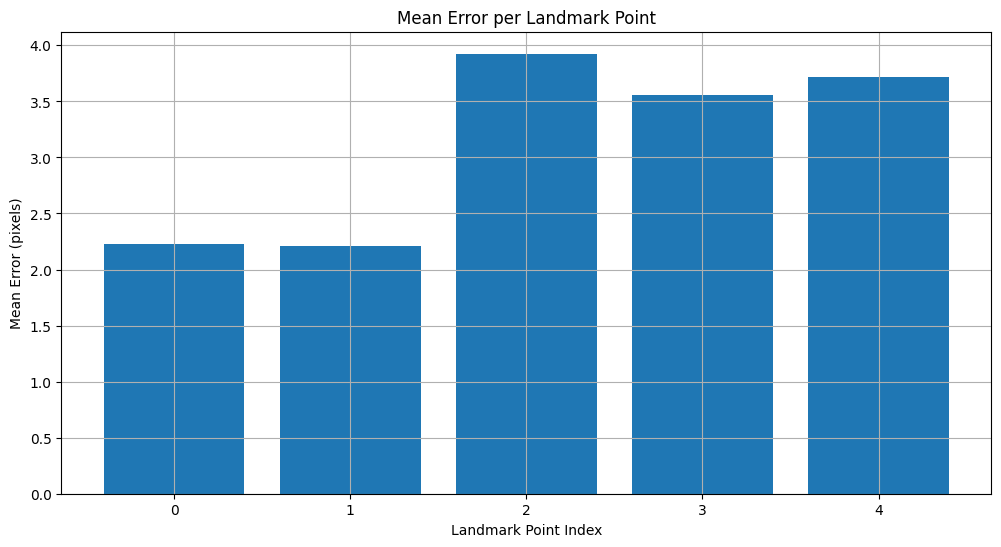

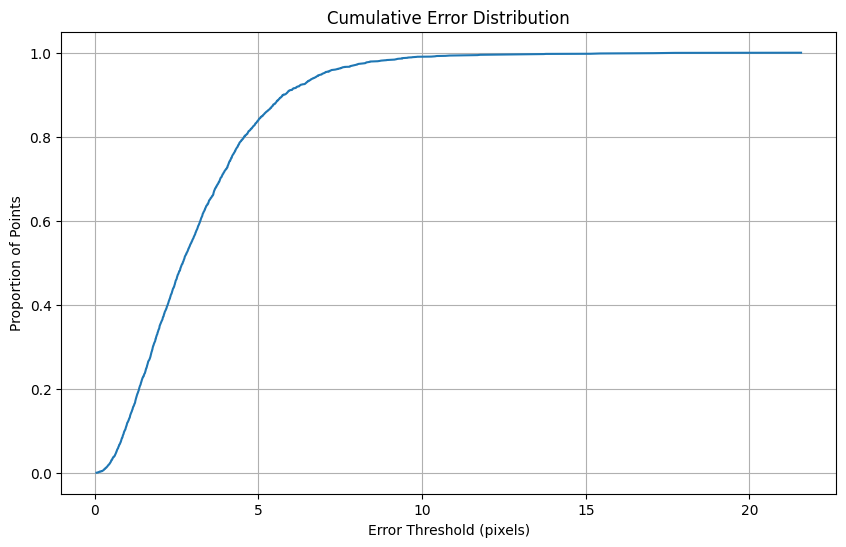


Robustness Analysis:
55.7% of points have error < 3 pixels
84.0% of points have error < 5 pixels
95.1% of points have error < 7 pixels
99.0% of points have error < 10 pixels


In [151]:
def analyze_errors(errors, point_count):
    """Generate comprehensive error analysis"""
    # point-wise errors
    mean_errors_per_point = np.mean(errors, axis=0)

    # making a bar chart showing mean error for each landmark
    plt.figure(figsize=(12, 6))
    plt.bar(range(point_count), mean_errors_per_point)
    plt.xlabel("Landmark Point Index")
    plt.ylabel("Mean Error (pixels)")
    plt.title("Mean Error per Landmark Point")
    plt.grid(True)
    plt.show()

    # making cumulative error distribution
    all_errors = errors.flatten()
    sorted_errors = np.sort(all_errors)
    cdf = np.arange(1, len(sorted_errors)+1) / len(sorted_errors)

    plt.figure(figsize=(10, 6))
    plt.plot(sorted_errors, cdf)
    plt.xlabel("Error Threshold (pixels)")
    plt.ylabel("Proportion of Points")
    plt.title("Cumulative Error Distribution")
    plt.grid(True)
    plt.show()

    #print how many predictions were under the error thresholds
    thresholds = [3, 5, 7, 10]
    robustness = [np.mean(all_errors < t)*100 for t in thresholds]

    print("\nRobustness Analysis:")
    for t, r in zip(thresholds, robustness):
        print(f"{r:.1f}% of points have error < {t} pixels")

print("\nAnalyzing errors...")
analyze_errors(val_errors, train_points_scaled.shape[1])

**Step 6: Test Prediction**

Running Test Prediction Visualization...


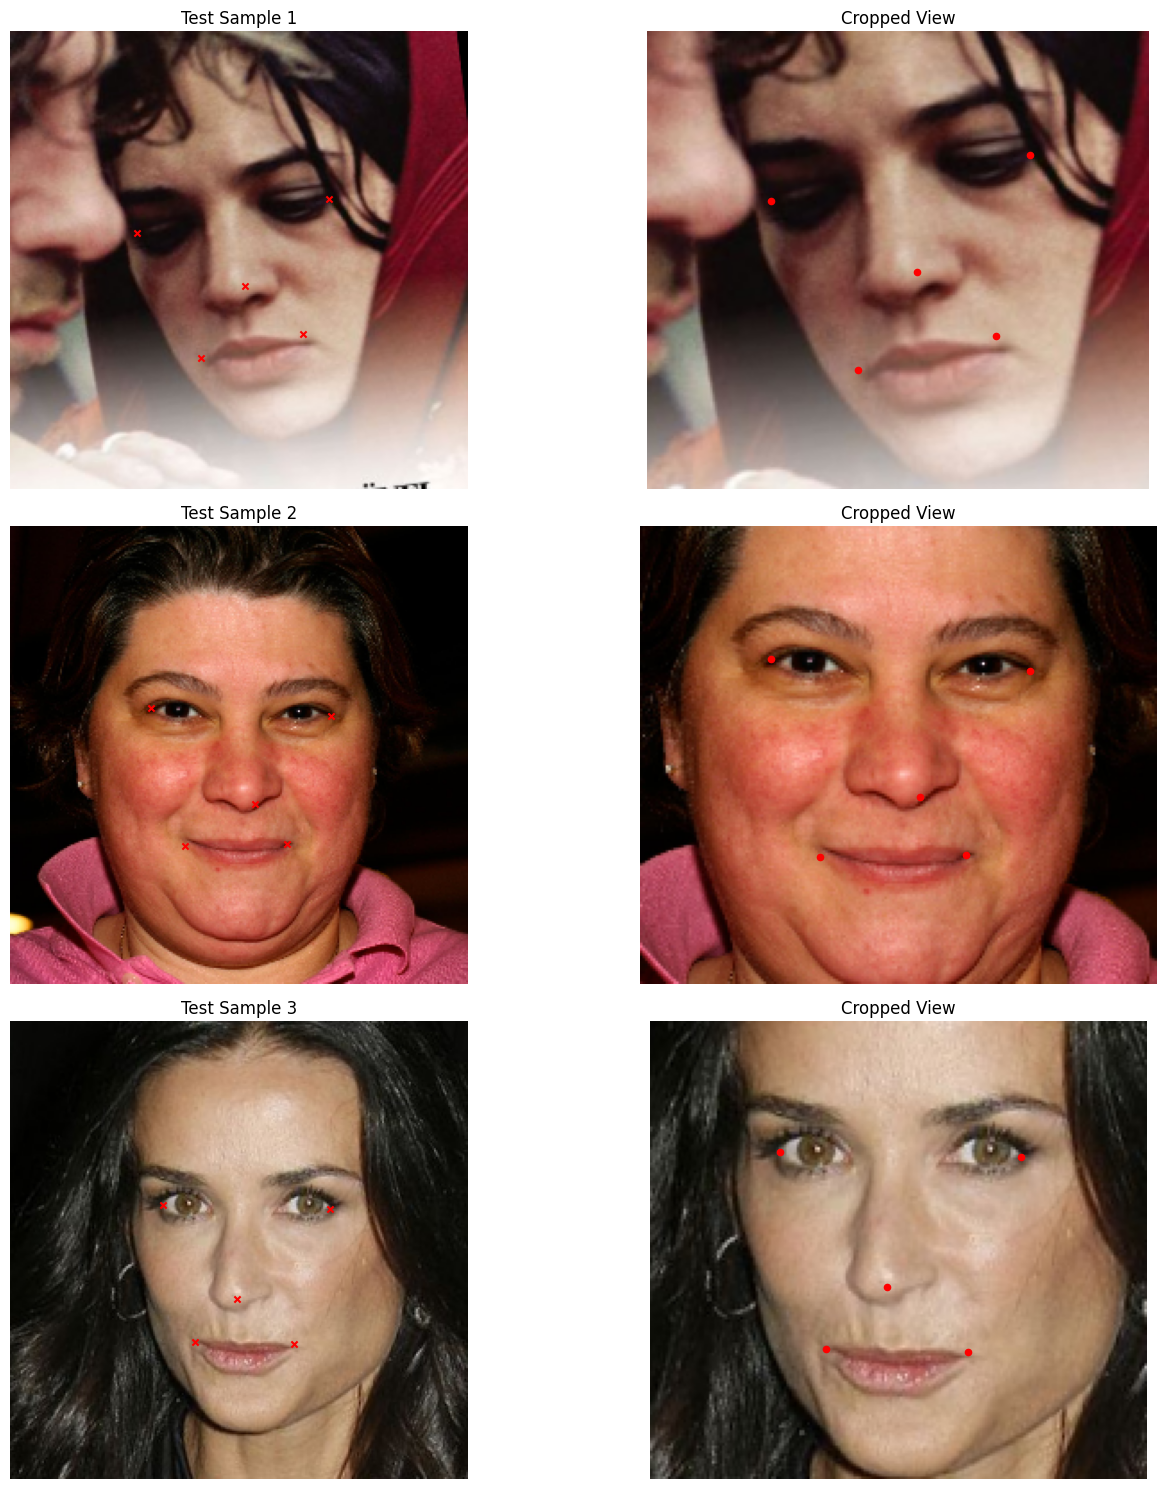

In [152]:
def show_test_predictions(test_images, test_predictions, num_samples=3):
    """Visualize predictions on test images"""
    try:
        plt.figure(figsize=(15, 5 * num_samples))
        for i in range(num_samples):
            img = test_images[i]
            points = test_predictions[i]

            # show the full image with landmarks
            plt.subplot(num_samples, 2, 2*i+1)
            plt.imshow(img, cmap='gray')
            plt.scatter(points[:, 0], points[:, 1], c='r', s=20, marker='x')
            plt.title(f"Test Sample {i+1}")
            plt.axis('off')

            # crop the image around the landmarks
            margin = 50
            x_min, y_min = np.min(points, axis=0).astype(int)
            x_max, y_max = np.max(points, axis=0).astype(int)
            y_start = max(0, y_min - margin)
            y_end = min(img.shape[0], y_max + margin)
            x_start = max(0, x_min - margin)
            x_end = min(img.shape[1], x_max + margin)

            # show cropped version with updated landmark positions
            plt.subplot(num_samples, 2, 2*i+2)
            cropped = img[y_start:y_end, x_start:x_end]
            plt.imshow(cropped, cmap='gray')
            plt.scatter(points[:,0]-x_start, points[:,1]-y_start, c='r', s=20)
            plt.title(f"Cropped View")
            plt.axis('off')

        plt.tight_layout()
        plt.show()
        return True
    except Exception as e:
        print(f"Visualization error: {str(e)}")
        return False

# generating the test predictions
test_predictions = model.predict(test_features)
test_predictions = test_predictions.reshape(len(test_images), *train_points_scaled.shape[1:])

# rescale predictions to match original image size
test_predictions_original = test_predictions.copy()
test_predictions_original[:, :, 0] /= scale_factors[0]
test_predictions_original[:, :, 1] /= scale_factors[1]


print("Running Test Prediction Visualization...")
if 'test_images' in locals() and 'test_predictions_original' in locals():
    show_test_predictions(test_images, test_predictions_original)
else:
    print("Required variables not found. Please run previous steps first.")

**Section 2: Error Distribution Analysis (Run Second)**


Running Error Distribution Analysis...


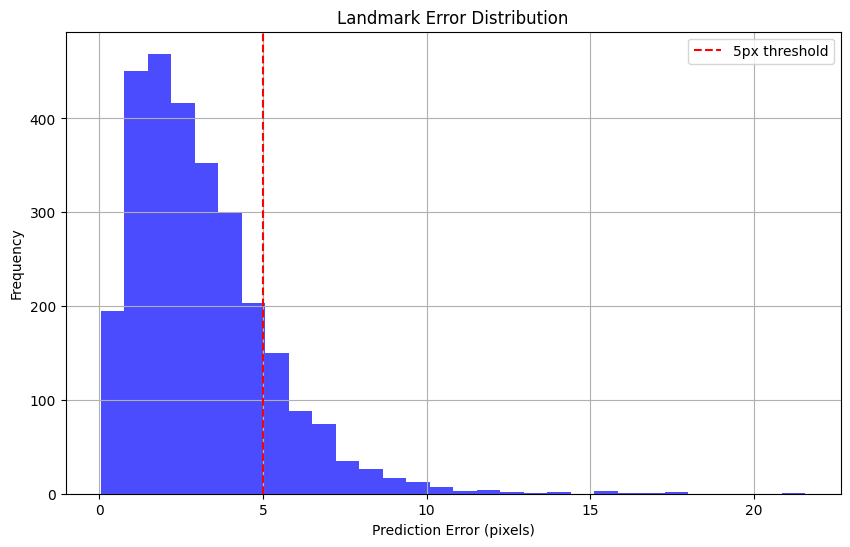

In [153]:
# histogram
def plot_error_distribution(errors):
    """Plot histogram of prediction errors"""

    try:
        # making the plot
        plt.figure(figsize=(10, 6))
        plt.hist(errors.flatten(), bins=30, color='blue', alpha=0.7)
        plt.axvline(x=5, color='red', linestyle='--', label='5px threshold')
        plt.xlabel('Prediction Error (pixels)')
        plt.ylabel('Frequency')
        plt.title('Landmark Error Distribution')
        plt.legend()
        plt.grid(True)
        plt.show()
        return True
    except Exception as e:
        print(f"Error plotting distribution: {str(e)}")
        return False


print("\nRunning Error Distribution Analysis...")
if 'val_errors' in locals():
    plot_error_distribution(val_errors)
else:
    print("Required 'val_errors' not found. Run model evaluation first.")

**Section 3: Landmark-Specific Accuracy (Run Third)**


=== FIXED LANDMARK ACCURACY ===
Adjusting: Using first 5 landmark names


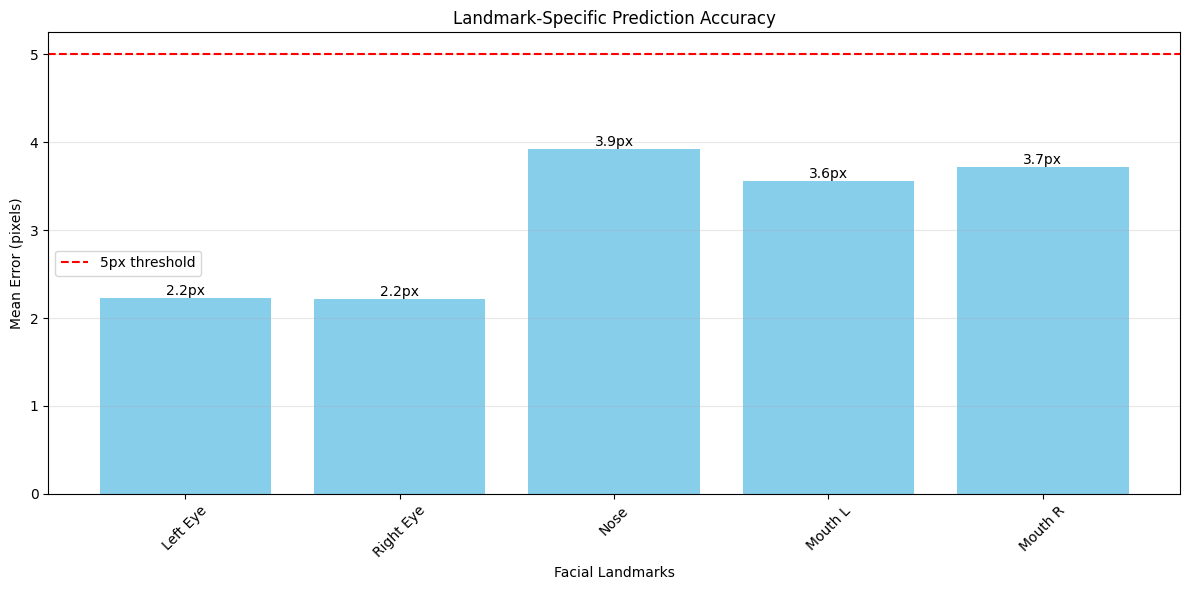

In [154]:
def plot_landmark_accuracy_fixed(errors, landmark_names=None):
    """Fixed version that matches error dimensions"""
    try:
        # geting the actual number of landmarks from errors array
        num_landmarks = errors.shape[1]

        # if no names are given then use default names
        if landmark_names is None:
            landmark_names = [f'Landmark {i}' for i in range(num_landmarks)]

        # cut list ifits too long
        elif len(landmark_names) != num_landmarks:
            print(f"Adjusting: Using first {num_landmarks} landmark names")
            landmark_names = landmark_names[:num_landmarks]

         # making the bar chart
        plt.figure(figsize=(12, 6))
        mean_errors = np.mean(errors, axis=0)
        bars = plt.bar(landmark_names, mean_errors, color='skyblue')

        # adding error values
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2, height,
                    f'{height:.1f}px',
                    ha='center', va='bottom')

        # add a horizontal red line at 5px as the error threshold
        plt.axhline(y=5, color='red', linestyle='--', label='5px threshold')
        plt.xlabel('Facial Landmarks')
        plt.ylabel('Mean Error (pixels)')
        plt.title('Landmark-Specific Prediction Accuracy')
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error in landmark accuracy: {str(e)}")

print("\n=== FIXED LANDMARK ACCURACY ===")
if 'val_errors' in locals():
    landmark_names = [
        'Left Eye', 'Right Eye', 'Nose',
        'Mouth L', 'Mouth R',
        'Eyebrow L', 'Eyebrow R',
        'Chin', 'Forehead'
    ]
    plot_landmark_accuracy_fixed(val_errors, landmark_names)
else:
    print("val_errors not found - run model evaluation first")

**Section 4: Confusion Matrix (Run Fourth)**

In [155]:
def show_confusion_matrix(errors, threshold=5):
    """Display binary accuracy confusion matrix"""
    try:
        correct = errors < threshold
        conf_matrix = np.array([
            [np.sum(correct), np.sum(~correct)],
            [0, 0]
        ])

         # calculating accuracy as % of correct predictions
        accuracy = np.mean(correct) * 100

        # printing the matrix
        print(f"\nConfusion Matrix ({threshold}px threshold):")
        print("+" + "-"*23 + "+")
        print("| {:^10} | {:^10} |".format("Correct", "Incorrect"))
        print("+" + "-"*23 + "+")
        print("| {:^10} | {:^10} |".format(conf_matrix[0,0], conf_matrix[0,1]))
        print("+" + "-"*23 + "+")
        print(f"\nAccuracy: {accuracy:.1f}% of points < {threshold}px error")
        return True

    except Exception as e:
        print(f"Error generating confusion matrix: {str(e)}")
        return False


# running the confusion matrix if val_errors exists
print("\nRunning Confusion Matrix Analysis...")
if 'val_errors' in locals():
    show_confusion_matrix(val_errors.flatten())
else:
    print("Required 'val_errors' not found. Run model evaluation first.")


Running Confusion Matrix Analysis...

Confusion Matrix (5px threshold):
+-----------------------+
|  Correct   | Incorrect  |
+-----------------------+
|    2364    |    451     |
+-----------------------+

Accuracy: 84.0% of points < 5px error


**Section 5: Design Decisions**

In [156]:
def show_design_decisions():
    """Display the design parameter table"""

    design_data = [
        ["Component", "Parameter", "Value", "Rationale"], # image resizing
        ["Preprocessing", "Size", "128x128", "Balance detail/computation"], # image enhancement
        ["", "Enhancement", "HistEQ+Unsharp", "Improve contrast/edges"], # feature extraction
        ["Features", "Method", "Dense SIFT", "Capture local patterns"], # grid density for SIFT descriptors
        ["", "Grid", "12x12", "Full coverage"], # regression model
        ["Model", "Type", "Ridge", "Handle correlations"], # regularization strength
        ["", "Alpha", "0.5", "Regularization"]
    ]

    print("\n{:<15} {:<15} {:<15} {:<40}".format(
        "Component", "Parameter", "Value", "Rationale"))
    print("-"*85)
    for row in design_data[1:]:
        print("{:<15} {:<15} {:<15} {:<40}".format(*row))

# Run this anytime
print("\nRunning Design Decisions Display...")
show_design_decisions()


Running Design Decisions Display...

Component       Parameter       Value           Rationale                               
-------------------------------------------------------------------------------------
Preprocessing   Size            128x128         Balance detail/computation              
                Enhancement     HistEQ+Unsharp  Improve contrast/edges                  
Features        Method          Dense SIFT      Capture local patterns                  
                Grid            12x12           Full coverage                           
Model           Type            Ridge           Handle correlations                     
                Alpha           0.5             Regularization                          


**Section 6: Final Metrics**

In [157]:
def show_final_metrics(errors):
    """Display all key metrics"""

    try:
      #list of performance metrics
        metrics = [
            ["Mean Error", f"{np.mean(errors):.2f} px"],
            ["Median Error", f"{np.median(errors):.2f} px"],
            ["Std Dev", f"{np.std(errors):.2f} px"],
            ["<5px Accuracy", f"{np.mean(errors < 5)*100:.1f}%"],
            ["Worst Point", f"{np.max(errors):.2f} px"]
        ]

        print("\n{:<20} {:<15}".format("Metric", "Value"))
        print("-"*35)
        for m in metrics:
            print("{:<20} {:<15}".format(*m))
        return True

    except Exception as e:
        print(f"Error displaying metrics: {str(e)}")
        return False


print("\nRunning Final Metrics Display...")

# checking if "val_errors" exists
if 'val_errors' in locals():
    show_final_metrics(val_errors)
else:
    print("Required 'val_errors' not found. Run model evaluation first.")


Running Final Metrics Display...

Metric               Value          
-----------------------------------
Mean Error           3.13 px        
Median Error         2.69 px        
Std Dev              2.15 px        
<5px Accuracy        84.0%          
Worst Point          21.58 px       


**6. Save predictions**

In [158]:
#generating predictions
test_predictions = model.predict(test_features)
Y_test_pred_pca = test_predictions.reshape(len(test_images), 5, 2)

# save predictions to CSV
import pandas as pd

def save_landmarks_to_csv(pred_landmarks, filename='final_predicted_landmarks.csv'):

    N, P, _ = pred_landmarks.shape
    #flatten landmarks into shape
    flattened = pred_landmarks.reshape(N, -1)
    #generating columns
    cols = [f'{axis}{i+1}' for i in range(P) for axis in ['x', 'y']]  # ['x1', 'y1', ..., 'x5', 'y5']
    df = pd.DataFrame(flattened, columns=cols)
    df.to_csv(filename, index=False)
    print(f"Saved predicted landmarks as '{filename}'")

#call funvtion
save_landmarks_to_csv(Y_test_pred_pca)


Saved predicted landmarks as 'final_predicted_landmarks.csv'
